# 2. Experimental variograms and model fitting

For each dataset:

1. **Lags** are spaced at the median nearest-neighbour well distance (about 100, 70 and 50 m for 25, 50 and 100 wells),
   out to 600 m, with tolerance half a lag and bandwidth three lags. The first lags therefore always have pairs.
2. **Eight measures** are calculated along 12 azimuths (0-165 deg, +/- 22.5 deg), with GSLIB `gamv` conventions:
   semivariogram (1), correlogram (4), general relative (5), pairwise relative (6), semivariogram of logarithms (7),
   rodogram (8, GSLIB 2 definition), cumulative semivariogram, and the semivariogram of normal scores. Each is
   standardized to a sill of 1 (correlogram: 1 - rho; rodogram: (R/R_all)^4).
3. **Azimuth** is inferred, as from a variogram map: the direction whose curve is lowest over lags <= 300 m.
4. **Fitting** is identical for every measure: pair-weighted least squares by grid search over spherical/exponential
   structure, nugget 0-0.9, major and minor range 30-1500 m.
5. **Accuracy** is the RMSE between the fitted model and the exhaustive truth variogram over every lag vector up to
   250 m (all directions), and the azimuth error for the anisotropic scenarios.

The implementation reproduces the original study's experimental variograms to 5e-12 when run with its lag settings
(`tests/check_core.py`).

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from vstudy import config as C, plots, analysis as A, wells as W, fitting, kriging
from vstudy.pipeline import run_study, build_truth, build_dataset, dataset_rng
from vstudy.variography import Truth, lag_settings
pd.set_option('display.precision', 3); pd.set_option('display.width', 160)
R = run_study('main')          # cached; run `python run_study.py main` first
P = run_study('pilot')

## One dataset, all eight measures

Anisotropic scenario, truth 0, 50 random wells. Dots: experimental values (size = pairs). Solid: fitted model.
Dashed: the truth's exhaustive variogram along the same azimuth.

lag settings: {'xlag': 60.0, 'xltol': 30.0, 'nlag': 10, 'bandwh': 180.0}


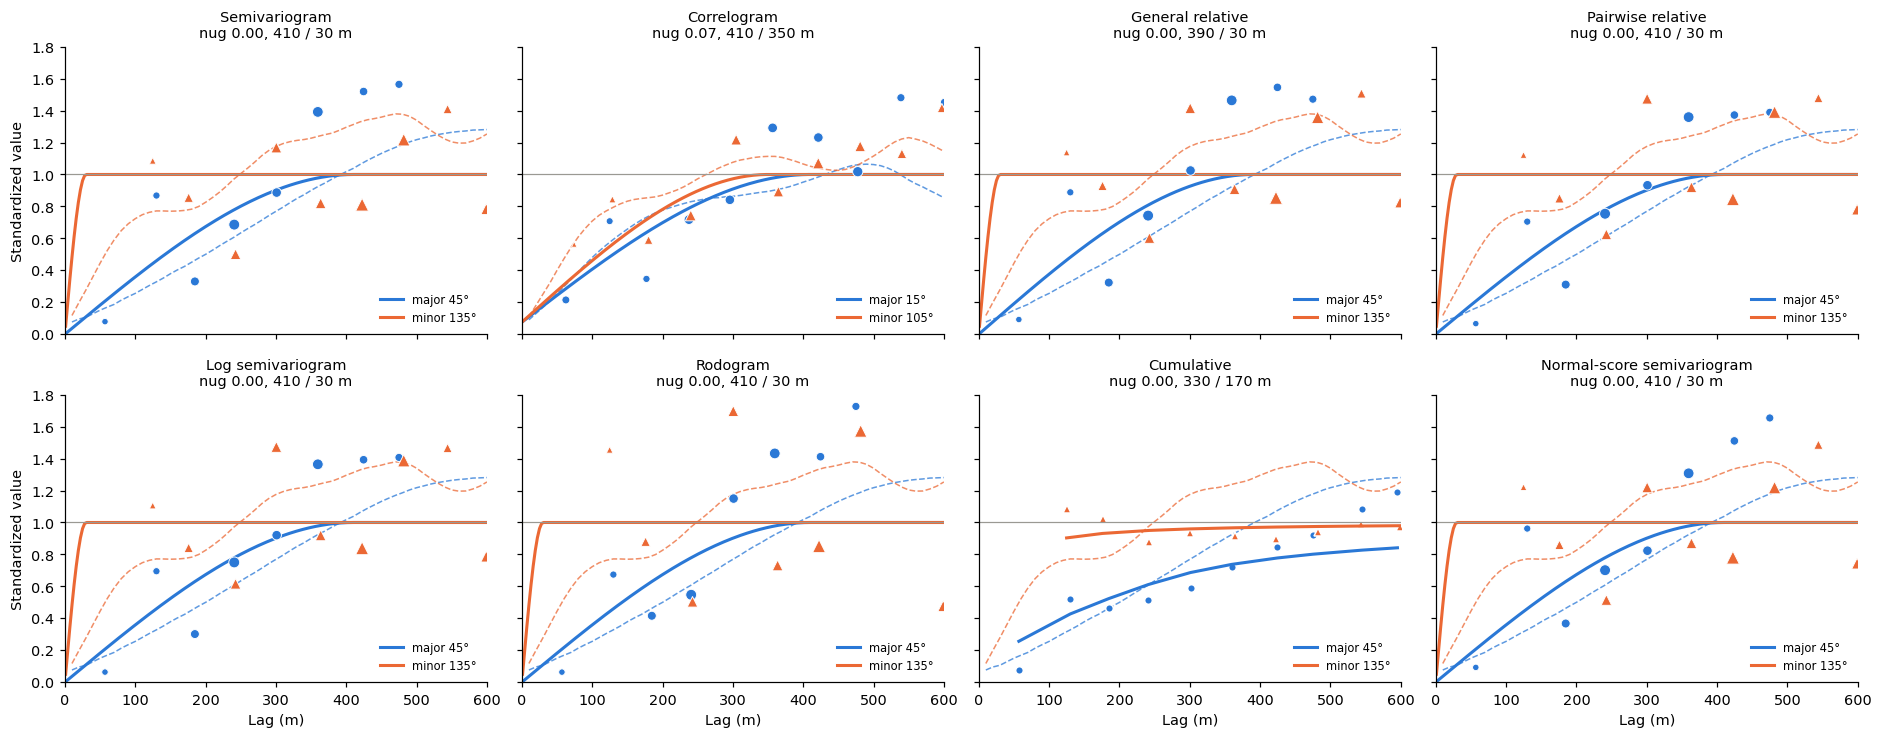

,it,nug,hmaj,hmin,azi,wrmse,vario_rmse
semivariogram,1.0,0.000,410.0,30.0,45.0,0.447,0.311
correlogram,1.0,0.075,410.0,350.0,15.0,0.226,0.135
general_relative,1.0,0.000,390.0,30.0,45.0,0.435,0.312
pairwise_relative,1.0,0.000,410.0,30.0,45.0,0.413,0.311
log,1.0,0.000,410.0,30.0,45.0,0.424,0.311
rodogram,1.0,0.000,410.0,30.0,45.0,0.688,0.311
cumulative,1.0,0.000,330.0,170.0,45.0,0.109,0.152
normal_score,1.0,0.000,410.0,30.0,45.0,0.470,0.311


In [2]:
ds = build_dataset('main', 'anisotropic', 0, 50, 'random')
phi = build_truth('main', 'anisotropic', 0)[0]
truth = Truth(phi)
print('lag settings:', {k: round(v, 1) for k, v in lag_settings(ds['wells']['x'], ds['wells']['y']).items()})
fig = plots.variogram_panels(ds['exp'], ds['models'], truth.curves()); plt.show()
pd.DataFrame(ds['models']).T.assign(vario_rmse=[truth.short_rmse(m) for m in ds['models'].values()])

## Reading the azimuth from the wells

Mean standardized semivariogram over lags <= 300 m, for each of the 12 directions. The lowest is the direction of
greatest continuity (true major direction for this scenario: 45 deg).

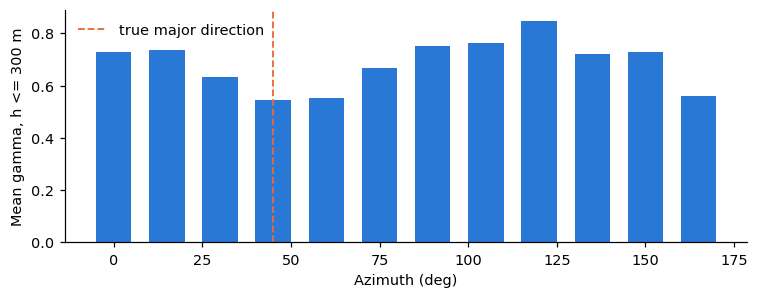

inferred order: [np.float64(45.0), np.float64(60.0), np.float64(30.0), np.float64(165.0)]


In [3]:
e = ds['exp']; e = e[(e.vtype == 'semivariogram') & (e.npairs >= C.MIN_PAIRS) & (e.h <= 300)]
score = e.groupby('azi').apply(lambda c: np.average(c.std_value, weights=c.npairs))
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.bar(score.index, score.values, width=10, color=plots.C_MAJ)
ax.axvline(45, color=plots.C_MIN, ls='--', lw=1.2, label='true major direction')
ax.set_xlabel('Azimuth (deg)'); ax.set_ylabel('Mean gamma, h <= 300 m'); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
print('inferred order:', fitting.major_direction(ds['exp'][ds['exp'].vtype == 'semivariogram'])[:4])

## Pilot: are any of the types redundant?

Rule stated before the pilot was run: a type is merged into an earlier type in the list if the two choose exactly the
same three development-well sites in at least 90% of pilot datasets (120 datasets on seeds not used in the main study).

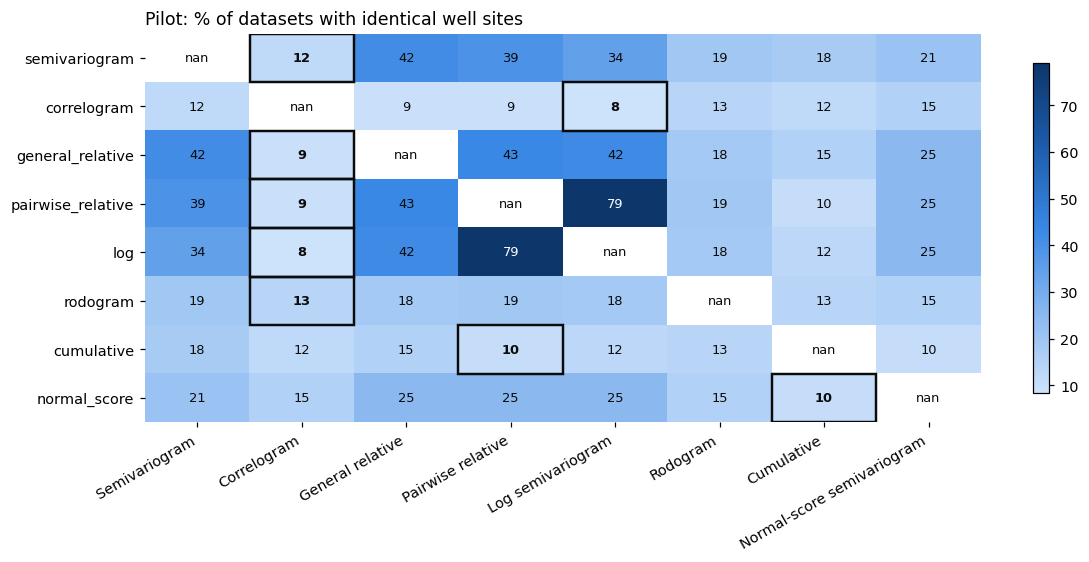

kept: ['semivariogram', 'correlogram', 'general_relative', 'pairwise_relative', 'log', 'rodogram', 'cumulative', 'normal_score']
merged: none - every type changes the decision often enough to keep


In [4]:
same = A.same_sites(P['decisions'])
kept, merged = A.trimmed_types(P['decisions'])
plots.heat(same.where(~np.eye(len(same), dtype=bool)), 'Pilot: % of datasets with identical well sites', fmt='{:.0f}'); plt.show()
print('kept:', kept); print('merged:', merged or 'none - every type changes the decision often enough to keep')

## Variogram accuracy in the main study

Short-range RMSE against the truth (lower is better). `truth fit` is the model fitted to the exhaustive truth variogram
itself: the floor set by the model family and the fitting procedure.

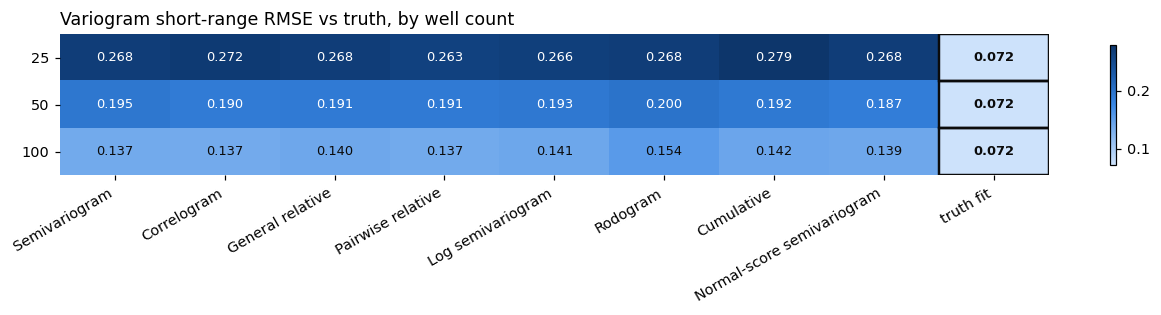

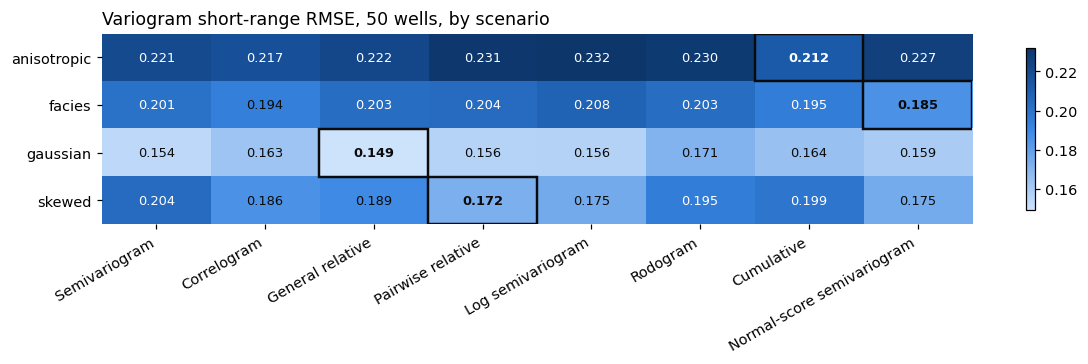

In [5]:
f = R['fits']
acc = A.by(f, 'vario_rmse', 'n_wells', 'vtype', C.VTYPES)
acc['truth fit'] = R['truths'].ref_vario_rmse.mean()
plots.heat(acc, 'Variogram short-range RMSE vs truth, by well count', fmt='{:.3f}'); plt.show()
plots.heat(A.by(f[f.n_wells == 50], 'vario_rmse', 'scenario', 'vtype', C.VTYPES), 'Variogram short-range RMSE, 50 wells, by scenario', fmt='{:.3f}'); plt.show()

Paired differences against the semivariogram, averaged within each truth model, with Holm correction over the 7
alternatives (negative = more accurate than the semivariogram).

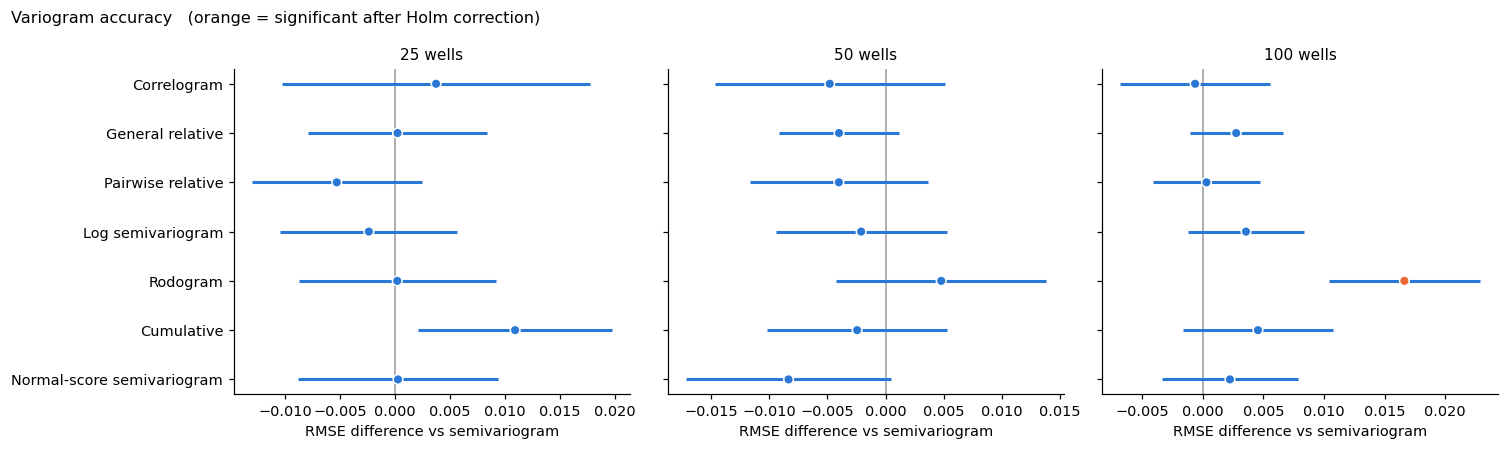

25 wells                       50 wells                           100 wells                     
                   mean_diff  ci_lo  ci_hi p_holm mean_diff  ci_lo      ci_hi p_holm  mean_diff  ci_lo  ci_hi p_holm
method                                                                                                              
correlogram        3.700e-03 -0.010  0.018   1.00    -0.005 -0.015  5.100e-03  1.000 -6.000e-04 -0.007  0.006  1.000
general_relative   2.000e-04 -0.008  0.008   1.00    -0.004 -0.009  1.200e-03  0.771  2.800e-03 -0.001  0.007  0.845
pairwise_relative -5.300e-03 -0.013  0.002   1.00    -0.004 -0.012  3.600e-03  1.000  3.000e-04 -0.004  0.005  1.000
log               -2.400e-03 -0.011  0.006   1.00    -0.002 -0.009  5.300e-03  1.000  3.600e-03 -0.001  0.008  0.845
rodogram           2.000e-04 -0.009  0.009   1.00     0.005 -0.004  1.380e-02  1.000  1.660e-02  0.010  0.023  0.000
cumulative         1.090e-02  0.002  0.020   0.11    -0.002 -0.010  5.300e-03  1.000  4.600e-03 -0.002  0.011  0.845
normal_score       2.000e-04 -0.009  0.009   1.00    -0.008 -0.017  5.000e-04  0.445  2.200e-03 -0.003  0.008  1.000

In [6]:
pt = A.paired_by_wells(f, 'vario_rmse', C.VTYPES[1:], col='vtype')
plots.forest(pt, 'RMSE difference vs semivariogram', 'Variogram accuracy'); plt.show()
pd.concat({k: v[['mean_diff', 'ci_lo', 'ci_hi', 'p_holm']] for k, v in pt.items()}, axis=1).round(4)

## Direction and range

Azimuth error (anisotropic and facies scenarios) and the share of fits at the shortest allowed minor range.

In [7]:
an = f[f.azi_err.notna()]
display(A.by(an, 'azi_err', 'n_wells', 'vtype', C.VTYPES).round(1).rename_axis('azimuth error (deg)'))
floor = f.assign(at_floor=100 * (f.hmin <= C.FIT_RANGES[0]))
A.by(floor, 'at_floor', 'n_wells', 'vtype', C.VTYPES).round(1).rename_axis('% fits at minimum range')

vtype,semivariogram,correlogram,general_relative,pairwise_relative,log,rodogram,cumulative,normal_score
azimuth error (deg),,,,,,,,
25,38.7,36.0,38.2,38.7,37.8,40.1,38.5,39.3
50,27.4,28.0,28.7,27.7,28.1,24.5,25.0,25.6
100,21.6,17.9,20.3,20.2,20.8,19.2,17.5,20.5


vtype,semivariogram,correlogram,general_relative,pairwise_relative,log,rodogram,cumulative,normal_score
% fits at minimum range,,,,,,,,
25,40.0,51.2,40.8,37.1,35.0,47.1,45.0,40.4
50,13.8,17.9,12.5,12.5,10.8,17.5,17.1,14.2
100,2.1,2.9,1.7,2.5,2.5,4.2,5.8,2.9


## Which type does cross-validation pick?

For each dataset, the type whose model re-predicts the wells best (closed-form leave-one-out kriging). This is
a choice a practitioner can make from the wells alone.

In [8]:
pick = f[f.picked]
(pd.crosstab(pick.scenario, pick.vtype, normalize='index') * 100).reindex(columns=C.VTYPES).round(0)

vtype,semivariogram,correlogram,general_relative,pairwise_relative,log,rodogram,cumulative,normal_score
scenario,,,,,,,,
anisotropic,11.0,26.0,13.0,7.0,3.0,9.0,23.0,8.0
facies,7.0,22.0,10.0,9.0,7.0,11.0,13.0,21.0
gaussian,6.0,27.0,8.0,7.0,3.0,18.0,20.0,10.0
skewed,13.0,23.0,12.0,8.0,8.0,11.0,17.0,7.0
